# 02 - Customer Segmentation with DBSCAN

Same data and features as notebook 01, but using density-based clustering. DBSCAN does not need K and labels outliers as **noise** (-1).

**Steps:** load and engineer features -> scale -> k-distance plot -> grid search for `eps` / `min_samples` -> fit -> profile clusters -> predict a new customer.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
SEED = 42

## 2. Load data and build features

In [2]:
df = pd.read_csv("../data/customer_segmentation.csv")
print("Shape:", df.shape)
print("Missing Income values:", df["Income"].isna().sum())

# Income has 24 missing values -> fill with the median (used later in the cluster profiles)
df["Income"] = df["Income"].fillna(df["Income"].median())

# Two behavioural features per customer
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["total_spent"] = df[mnt_cols].sum(axis=1)          # total amount spent across all product categories
df["purchase_count"] = df[purchase_cols].sum(axis=1)  # total number of purchases across all channels

FEATURES = ["total_spent", "purchase_count"]
print(df[FEATURES].describe().round(2))

Shape: (2240, 29)
Missing Income values: 24
       total_spent  purchase_count
count      2240.00         2240.00
mean        605.80           14.86
std         602.25            7.68
min           5.00            0.00
25%          68.75            8.00
50%         396.00           15.00
75%        1045.50           21.00
max        2525.00           44.00


## 3. Scale features

DBSCAN's `eps` is a distance, so the features must be on a comparable scale.

In [3]:
# One scaler for the whole project (notebooks 01, 02 and 03) so results are comparable.
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

## 4. k-distance plot

Sorted distance to each point's 10th nearest neighbour. The "knee" of the curve suggests a reasonable `eps` range.

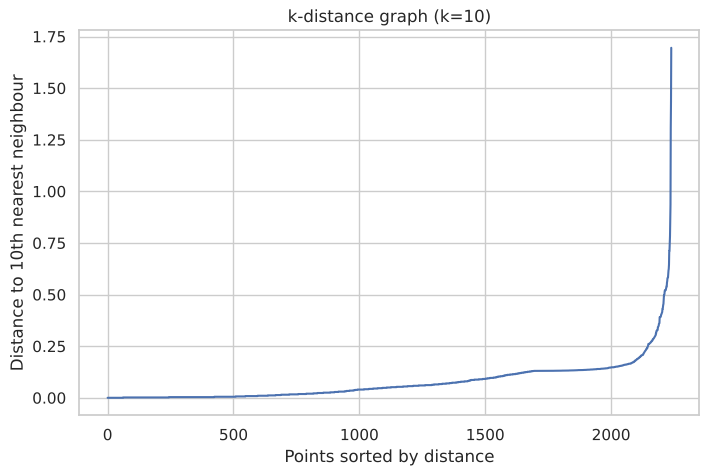

In [4]:
K_NEIGHBORS = 10
distances, _ = NearestNeighbors(n_neighbors=K_NEIGHBORS).fit(X).kneighbors(X)
kdist = np.sort(distances[:, K_NEIGHBORS - 1])

plt.figure(figsize=(8, 5))
plt.plot(kdist)
plt.title(f"k-distance graph (k={K_NEIGHBORS})")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 10th nearest neighbour")
plt.savefig("../images/dbscan_k_distance.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Grid search for `eps` and `min_samples`

**Important:** silhouette is computed on non-noise points only, so a tiny `eps` can score very high just by labelling most customers as noise. To avoid that, a candidate is only eligible if **noise <= 10 %** and it produces **2 to 10 clusters**. Among eligible candidates we pick the highest silhouette.

In [5]:
MAX_NOISE = 0.10
EPS_VALUES = np.round(np.arange(0.05, 1.55, 0.05), 2)
MIN_SAMPLES_VALUES = [5, 10, 15, 20, 30, 40]

records = []
for eps in EPS_VALUES:
    for ms in MIN_SAMPLES_VALUES:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        sil_score = np.nan
        if n_clusters >= 2:
            sil_score = silhouette_score(X[mask], labels[mask])
        records.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                        "noise_%": round((~mask).mean() * 100, 1), "silhouette": sil_score})

grid = pd.DataFrame(records)
print(f"Combinations tried: {len(grid)}  |  with >= 2 clusters: {grid['silhouette'].notna().sum()}")

print("\nTop 5 by raw silhouette (note the noise %):")
print(grid.sort_values("silhouette", ascending=False).head(5).round(4).to_string(index=False))

eligible = grid[(grid["silhouette"].notna()) & (grid["noise_%"] <= MAX_NOISE * 100) & (grid["clusters"].between(2, 10))]
print("\nTop 5 eligible (noise <= 10 %, 2-10 clusters):")
print(eligible.sort_values("silhouette", ascending=False).head(5).round(4).to_string(index=False))

best = eligible.sort_values("silhouette", ascending=False).iloc[0]
BEST_EPS, BEST_MS = float(best["eps"]), int(best["min_samples"])
print(f"\nSelected: eps={BEST_EPS}, min_samples={BEST_MS}")

Combinations tried: 180  |  with >= 2 clusters: 27

Top 5 by raw silhouette (note the noise %):
 eps  min_samples  clusters  noise_%  silhouette
0.05           40         6     67.9      0.7423
0.05           30         6     67.6      0.7369
0.10           40         8     61.1      0.6874
0.05           15        12     56.2      0.6654
0.05           20        10     58.9      0.6630

Top 5 eligible (noise <= 10 %, 2-10 clusters):
 eps  min_samples  clusters  noise_%  silhouette
0.20           20         3      5.8      0.3448
0.20           15         2      4.2      0.3423
0.30           40         2      3.4      0.3403
0.25           30         3      6.6      0.3359
0.20           30         4      9.8      0.3352

Selected: eps=0.2, min_samples=20


## 6. Fit the final model

In [6]:
db = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS).fit(X)
df["cluster"] = db.labels_

mask = db.labels_ != -1
n_clusters = len(set(db.labels_[mask]))
print(f"Clusters found : {n_clusters}")
print(f"Noise points   : {(~mask).sum()} ({(~mask).mean()*100:.1f} %)")
print(f"Silhouette (non-noise points only): {silhouette_score(X[mask], db.labels_[mask]):.4f}")
print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index().to_string())

Clusters found : 3
Noise points   : 131 (5.8 %)
Silhouette (non-noise points only): 0.3448

Cluster sizes:
cluster
-1     131
 0     361
 1    1639
 2     109


## 7. Visualize the clusters

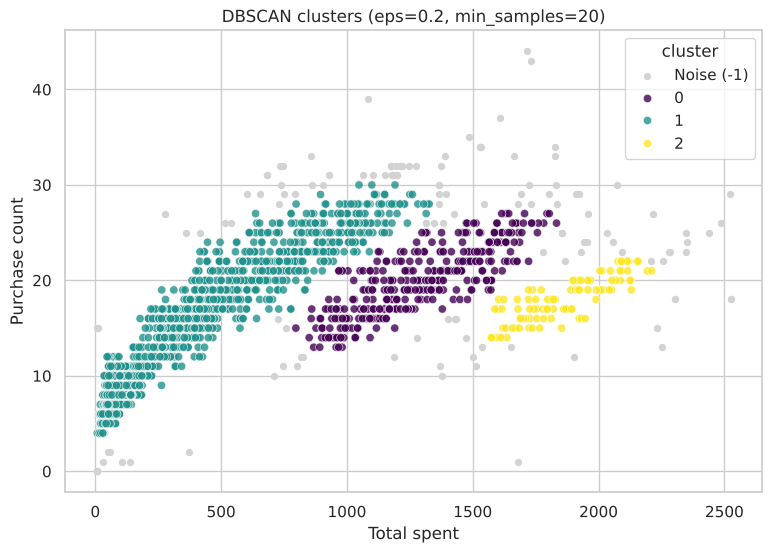

In [7]:
plt.figure(figsize=(9, 6))
noise = df[df["cluster"] == -1]
plt.scatter(noise["total_spent"], noise["purchase_count"], c="lightgray", s=18, label="Noise (-1)")
sns.scatterplot(data=df[df["cluster"] != -1], x="total_spent", y="purchase_count",
                hue="cluster", palette="viridis", alpha=0.8)
plt.title(f"DBSCAN clusters (eps={BEST_EPS}, min_samples={BEST_MS})")
plt.xlabel("Total spent")
plt.ylabel("Purchase count")
plt.legend(title="cluster")
plt.savefig("../images/dbscan_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Cluster profiles (noise excluded)

In [8]:
profile = (df[df["cluster"] != -1].groupby("cluster")
             .agg(customers=("cluster", "size"),
                  avg_total_spent=("total_spent", "mean"),
                  avg_purchase_count=("purchase_count", "mean"),
                  avg_income=("Income", "mean"),
                  avg_recency_days=("Recency", "mean"))
             .round(2))
profile["share_of_all_%"] = (profile["customers"] / len(df) * 100).round(1)
profile

,customers,avg_total_spent,avg_purchase_count,avg_income,avg_recency_days,share_of_all_%
cluster,,,,,,
0,361,1294.19,20.02,72585.59,52.45,16.1
1,1639,312.30,12.82,44271.32,48.69,73.2
2,109,1864.38,18.07,80465.55,47.45,4.9


## 9. Predict the cluster of a new customer

DBSCAN has no `predict()`. The standard approach: a new point joins the cluster of its nearest **core point** if that core point is within `eps`; otherwise it is **noise (-1)**.

In [9]:
core_points = X[db.core_sample_indices_]
core_labels = db.labels_[db.core_sample_indices_]

def predict_cluster(total_spent, purchase_count):
    """Return the DBSCAN cluster id for a new customer, or -1 if it is noise."""
    point = scaler.transform(pd.DataFrame([[total_spent, purchase_count]], columns=FEATURES))
    dist = np.linalg.norm(core_points - point, axis=1)
    nearest = dist.argmin()
    return int(core_labels[nearest]) if dist[nearest] <= db.eps else -1

for spent, n in [(50, 5), (700, 20), (1800, 25), (10000, 30)]:
    print(f"total_spent={spent:>6}, purchase_count={n:>3} -> cluster {predict_cluster(spent, n)}")

total_spent=    50, purchase_count=  5 -> cluster 1
total_spent=   700, purchase_count= 20 -> cluster 1
total_spent=  1800, purchase_count= 25 -> cluster 0
total_spent= 10000, purchase_count= 30 -> cluster -1
